# Colonoscopy polyp detection: YOLO11n vs Faster R-CNN, analysis

A computer-aided detection (CADe) system for colonoscopy draws a box around every polyp in the video frame so that
fewer polyps are overlooked. This notebook compares two families of detectors for that job on Kvasir-SEG
(1,000 colonoscopy frames with polyp boxes and masks): the one-stage **YOLO11n** (Ultralytics, 2.6 M parameters) and
the two-stage **Faster R-CNN** with a MobileNetV3-Large FPN backbone (torchvision, 19.0 M parameters). Both start from
COCO weights, see the same 780 training frames at the same input size (longer side 416 px), get a similar training
budget (about 1.5-2 minutes on a laptop RTX 4050) and are scored by the same pycocotools code.

| Part | Question | Validation |
|---|---|---|
| Data | Are the boxes trustworthy? | SHA-256 pins, official split, boxes vs segmentation masks |
| Accuracy | Which detector finds and localises polyps better? | COCO AP on 120 held-out frames, paired bootstrap, Holm correction |
| Reference | Is the pipeline in a plausible range? | Published results on the same official split (Jha et al., 2021) |
| Operating point | What happens at a threshold a CADe system would use? | threshold fixed on validation, counts of found and missed polyps |
| Size | Are small or large polyps harder? | AP and recall per size bin |
| Augmentation | How much does each detector rely on augmentation? | the same runs with every augmentation off |
| Speed | What does each cost at inference? | batch-1 latency, same clock for both |
| Errors | What do the mistakes look like? | false positives and misses at the operating point |

Everything below reads the tables written by `scripts/run_pipeline.py`. Run settings:

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES, FIG = ROOT / 'reports' / 'results', ROOT / 'reports' / 'figures'
pd.set_option('display.precision', 3)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 180)
meta = json.loads((RES / 'run_metadata.json').read_text())
{k: meta[k] for k in ['yolo_config', 'frcnn_config', 'timings_s', 'device']}

{'yolo_config': {'weights': 'yolo11n.pt',
  'img_size': 416,
  'epochs': 15,
  'patience': 6,
  'batch_size': 16,
  'augment': True,
  'seed': 0,
  'aug_overrides': {'flipud': 0.5, 'close_mosaic': 5}},
 'frcnn_config': {'img_size': 416,
  'epochs': 8,
  'patience': 4,
  'batch_size': 8,
  'lr': 0.01,
  'momentum': 0.9,
  'weight_decay': 0.0001,
  'warmup_iters': 100,
  'augment': True,
  'seed': 0,
  'pretrained': True},
 'timings_s': {'data': 5.1,
  'training': 347.8,
  'inference': 4.0,
  'speed': 32.3,
  'evaluation': 8.4},
 'device': 'NVIDIA GeForce RTX 4050 Laptop GPU'}

## 1. Data and checks

The archive and the official 880 / 120 split lists match their pinned SHA-256 digests, and the counts match the
dataset page and Jha et al. (2021) (12 of 12 checks). The JSON boxes were also checked against the segmentation
masks: of the 1,064 boxes that are not slivers, 99.0% match the bounding box of a mask component with IoU >= 0.9
(median 0.991; the JSON corners sit one pixel up and left of the mask, a coordinate convention). Eleven boxes are
looser than their mask (IoU 0.02-0.90), ten of them because the box extends 40-230 px beyond the mask on the top or
left side. Every mask pixel lies inside a JSON box.

Seven JSON boxes are slivers whose shorter side is 1-3 pixels (for example a 129 x 1 px strip on the top edge). They
are annotation artefacts along a mask edge or the frame border, not polyps, and are dropped by a rule fixed before any model was trained (shorter
side < 5 px); three of them are in the test set, so the test set has 127 polyps in 120 frames. Section 10 repeats the
evaluation with them kept.

The size bins use the box area as a share of the frame, because the frames range from 332 x 487 to 1920 x 1072
pixels: small < 10%, medium 10-25%, large > 25% (the training boxes' tertiles are 10% and 23%). Most polyps are large
by COCO standards; a "small" polyp here covers a median 5.4% of the frame (interquartile range 3.5-7.6%).

In [2]:
pd.read_csv(RES / 'data_crosscheck.csv')

,check,expected,observed,match,source
0,kvasir-seg.zip SHA-256,03b30e21d584e04facf49397a2576738fd626815771afbbf788f74a7153478f7,03b30e21d584e04facf49397a2576738fd626815771afbbf788f74a7153478f7,True,pinned at download
1,kvasir-seg.zip bytes,46227172,46227172,True,HTTP Content-Length
2,images,1000,1000,True,dataset page
3,masks,1000,1000,True,dataset page
4,images in the box JSON,1000,1000,True,dataset page
5,official training list,880,880,True,Jha et al. (2021)
6,official test list,120,120,True,Jha et al. (2021)
7,train / test overlap,0,0,True,split lists
8,split ids found in the box JSON,1000,1000,True,split lists vs JSON
9,JSON width/height = JPEG size,1000,1000,True,JSON vs image files


In [3]:
pd.read_csv(RES / 'box_mask_agreement.csv')

,statistic,value
0,JSON boxes,1071.000
1,sliver boxes (shorter side < 5 px),7.000
2,non-sliver boxes with a mask component at IoU >= 0.9,0.990
3,non-sliver boxes with a mask component at IoU >= 0.95,0.979
4,median best IoU with a mask component (non-sliver),0.991
5,minimum best IoU with a mask component (non-sliver),0.020
6,median x0 offset JSON - mask (px),-1.000
7,median y0 offset JSON - mask (px),-1.000
8,median x1 offset JSON - mask (px),0.000
9,median y1 offset JSON - mask (px),0.000


In [4]:
pd.read_csv(RES / 'split_summary.csv')

,split,images,boxes,sliver_boxes_dropped,images_with_2plus_polyps,small_polyps,medium_polyps,large_polyps,median_rel_area,median_image_width
0,train,780,829,3,36,278,302,249,0.150,620.0
1,val,100,108,1,6,33,39,36,0.163,622.0
2,test,120,127,3,7,51,41,35,0.147,622.0


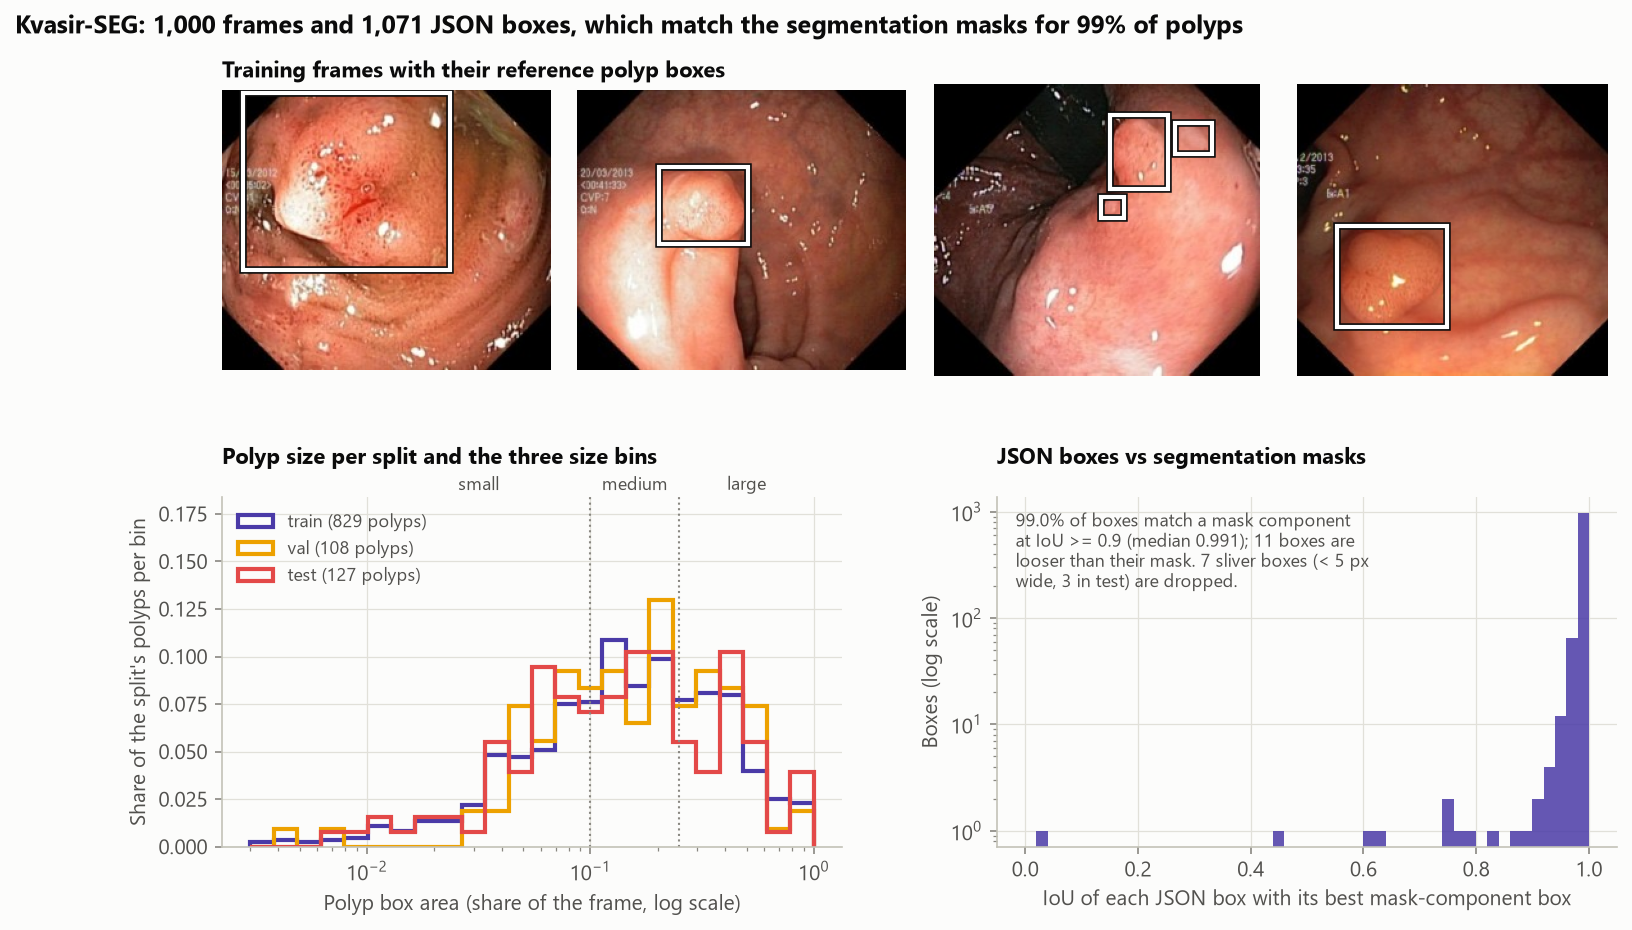

In [5]:
display(Image(FIG / '00_data.png'))

## 2. Training

| | YOLO11n | Faster R-CNN (MobileNetV3-Large FPN) |
|---|---|---|
| Weights | COCO (Ultralytics `yolo11n.pt`) | COCO (`FasterRCNN_MobileNet_V3_Large_FPN_Weights.COCO_V1`), new 2-class head |
| Recipe | Ultralytics defaults: AdamW (lr 0.002 chosen by `optimizer=auto`), batch 16, AMP, 15 epochs | SGD (lr 0.01, momentum 0.9), warm-up + cosine, batch 8, fp16 autocast, 8 epochs |
| Augmentation | mosaic, HSV, scale, translate, horizontal and vertical flips (mosaic off for the last 5 epochs) | flips, zoom-in crops, brightness / contrast / saturation jitter |
| Kept epoch | best validation mAP@[.5:.95] (Ultralytics' metric) | best validation mAP@[.5:.95] (pycocotools) |

The epoch budgets were set from a timing probe so that each detector trains for about 1.5-2 GPU-minutes. Both
augmented models kept their **last** epoch (YOLO11n 15 of 15, Faster R-CNN 8 of 8), so both were still improving
when the budget ran out; the comparison is of two short fine-tunes, not of converged models.

In [6]:
pd.read_csv(RES / 'models.csv')

,model,key,detector,augmentation,epochs_run,max_epochs,best_epoch,best_val_AP,train_seconds,params,cache_key
0,YOLO11n,yolo11n-aug,yolo,True,15,15,15,0.691,107.278,2604883,2dfca4f064ff
1,YOLO11n (no aug.),yolo11n-none,yolo,False,15,15,13,0.642,71.423,2604883,7037ec09e52d
2,Faster R-CNN,frcnn-aug,frcnn,True,8,8,8,0.665,97.014,18954629,4f6874fb90d6
3,Faster R-CNN (no aug.),frcnn-none,frcnn,False,8,8,8,0.623,71.893,18954629,3224ba8b69e7


In [7]:
h = pd.read_csv(RES / 'training_history.csv')
h.pivot_table(index='epoch', columns='model', values='val_AP').round(3)

model,Faster R-CNN,Faster R-CNN (no aug.),YOLO11n,YOLO11n (no aug.)
epoch,,,,
1,0.512,0.471,0.364,0.302
2,0.585,0.518,0.289,0.166
3,0.553,0.582,0.367,0.167
4,0.564,0.557,0.363,0.353
5,0.612,0.599,0.501,0.384
6,0.654,0.607,0.500,0.481
7,0.664,0.618,0.548,0.536
8,0.665,0.623,0.629,0.511
9,NaN,NaN,0.612,0.559


## 3. Accuracy on the 120 test frames

| | YOLO11n | Faster R-CNN |
|---|---:|---:|
| AP50 | 0.866 | 0.886 |
| AP75 | 0.767 | 0.761 |
| mAP@[.5:.95] | 0.671 | 0.646 |
| AP@[.25:.75] (Jha et al.'s summary metric) | 0.867 | 0.878 |

No difference between the two detectors is significant. The largest, YOLO11n's +0.025 mAP@[.5:.95], has a 95%
bootstrap CI of [-0.011, +0.060] (p = 0.17 before correction), and Faster R-CNN's +0.020 AP50 has a CI of
[-0.014, +0.054]. On small polyps YOLO11n is ahead by 0.055 AP (unadjusted p = 0.035), which does not survive the
Holm correction over the 11 comparisons (adjusted p = 0.35). The precision-recall curves overlap almost everywhere.

In [8]:
m = pd.read_csv(RES / 'coco_metrics.csv')
m[(m.split == 'test') & (m.ground_truth == 'cleaned')].drop(columns=['key', 'split', 'ground_truth'])

,model,AP,AP50,AP75,AR,AP_small,AP_medium,AP_large,AR_small,AR_medium,AR_large,AP_25_75,AP25
1,YOLO11n,0.671,0.866,0.767,0.802,0.699,0.695,0.619,0.808,0.834,0.757,0.867,0.928
4,YOLO11n (no aug.),0.600,0.827,0.705,0.720,0.578,0.682,0.554,0.692,0.759,0.714,0.812,0.892
7,Faster R-CNN,0.646,0.886,0.761,0.718,0.644,0.693,0.618,0.702,0.766,0.686,0.878,0.943
10,Faster R-CNN (no aug.),0.624,0.898,0.747,0.702,0.649,0.675,0.562,0.712,0.739,0.643,0.876,0.944


In [9]:
c = pd.read_csv(RES / 'metric_cis.csv')
c.assign(ci=c.ci_low.round(3).astype(str) + ' to ' + c.ci_high.round(3).astype(str)).pivot_table(index='model', columns='metric', values='ci', aggfunc='first')[['AP', 'AP50', 'AP75', 'AP_25_75', 'AP_small', 'AP_medium', 'AP_large']]

metric,AP,AP50,AP75,AP_25_75,AP_small,AP_medium,AP_large
model,,,,,,,
Faster R-CNN,0.59 to 0.705,0.824 to 0.943,0.686 to 0.841,0.824 to 0.931,0.562 to 0.728,0.621 to 0.773,0.52 to 0.728
Faster R-CNN (no aug.),0.568 to 0.681,0.833 to 0.953,0.661 to 0.834,0.819 to 0.929,0.577 to 0.718,0.592 to 0.764,0.462 to 0.674
YOLO11n,0.616 to 0.733,0.81 to 0.927,0.69 to 0.849,0.812 to 0.923,0.617 to 0.785,0.614 to 0.785,0.522 to 0.721
YOLO11n (no aug.),0.54 to 0.665,0.76 to 0.892,0.622 to 0.791,0.748 to 0.876,0.495 to 0.678,0.591 to 0.776,0.44 to 0.671


In [10]:
pd.read_csv(RES / 'significance.csv').round(4)

,model,versus,metric,value,value_versus,diff,diff_ci_low,diff_ci_high,p,p_holm
0,YOLO11n,Faster R-CNN,AP,0.671,0.646,2.500e-02,-0.011,0.060,0.174,1.000
1,YOLO11n,Faster R-CNN,AP50,0.866,0.886,-1.980e-02,-0.054,0.014,0.303,1.000
2,YOLO11n,Faster R-CNN,AP75,0.767,0.761,6.400e-03,-0.065,0.071,0.880,1.000
3,YOLO11n,Faster R-CNN,AP_25_75,0.867,0.878,-1.120e-02,-0.041,0.015,0.455,1.000
4,YOLO11n,Faster R-CNN,AP_small,0.699,0.644,5.520e-02,0.000,0.106,0.035,0.347
5,YOLO11n,Faster R-CNN,AP_medium,0.695,0.693,2.100e-03,-0.057,0.067,0.859,1.000
6,YOLO11n,Faster R-CNN,AP_large,0.619,0.618,8.000e-04,-0.071,0.071,0.956,1.000
7,YOLO11n,YOLO11n (no aug.),AP,0.671,0.600,7.060e-02,0.029,0.115,0.002,0.016
8,YOLO11n,YOLO11n (no aug.),AP50,0.866,0.827,3.960e-02,0.002,0.084,0.060,0.539
9,Faster R-CNN,Faster R-CNN (no aug.),AP,0.646,0.624,2.140e-02,-0.012,0.053,0.215,1.000


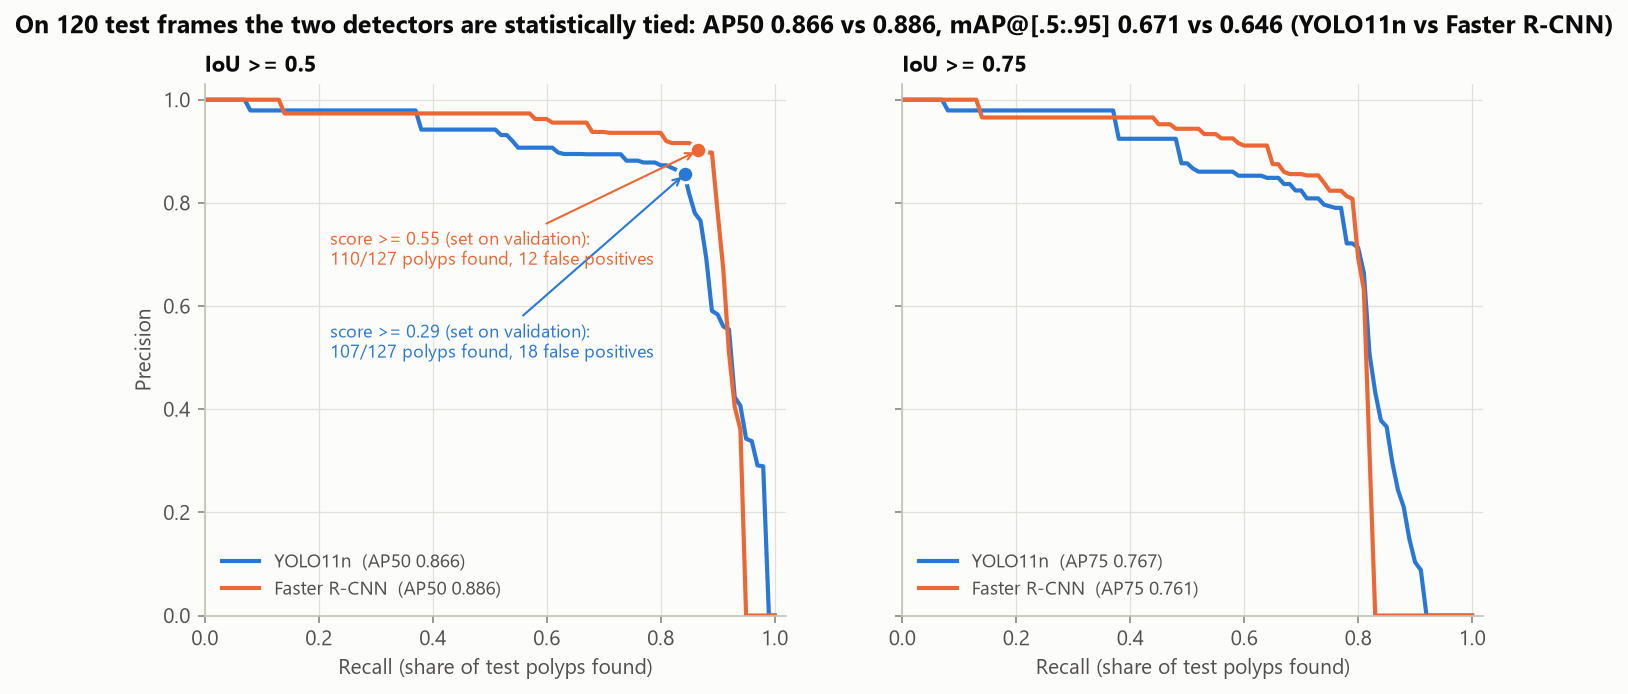

In [11]:
display(Image(FIG / '01_pr_curves.png'))

## 4. Localisation and the published reference

AP against the IoU threshold shows where the detectors differ: they are equal up to about IoU 0.8, and above it
YOLO11n keeps more of its AP (0.55 vs 0.46 at IoU 0.85, 0.34 vs 0.25 at 0.9, 0.10 vs 0.01 at 0.95). These single
thresholds were not tested separately; their contribution is already inside the mAP@[.5:.95] difference, which is
not significant. At the operating point, YOLO11n's correct boxes overlap the reference box by a mean IoU of 0.880
against 0.862.

Jha et al. (2021) trained larger detectors (Faster R-CNN ResNet-50, RetinaNet ResNet-101, YOLOv3 and YOLOv4 with
Darknet-53) on the same official split at 512 x 512 and reported AP50 0.82-0.91, AP75 0.57-0.76 and
AP@[.25:.75] 0.79-0.87. Both models here land in the upper part of that range (AP50 0.866 and 0.886, AP75 0.767 and 0.761, AP@[.25:.75] 0.867 and
0.878). Their AP used a different interpolation, and they describe the 120 images as their validation set, so the
images may also have guided their model selection; this is a plausibility check of the pipeline, not a
like-for-like ranking.

In [12]:
a = pd.read_csv(RES / 'ap_by_iou.csv')
a.pivot_table(index='iou', columns='model', values='AP').round(3)

model,Faster R-CNN,Faster R-CNN (no aug.),YOLO11n,YOLO11n (no aug.)
iou,,,,
0.25,0.943,0.944,0.928,0.892
0.30,0.942,0.941,0.928,0.886
0.35,0.928,0.932,0.902,0.864
0.40,0.915,0.917,0.893,0.846
0.45,0.910,0.916,0.871,0.842
0.50,0.886,0.898,0.866,0.827
0.55,0.883,0.877,0.866,0.808
0.60,0.872,0.864,0.852,0.782
0.65,0.829,0.813,0.841,0.756


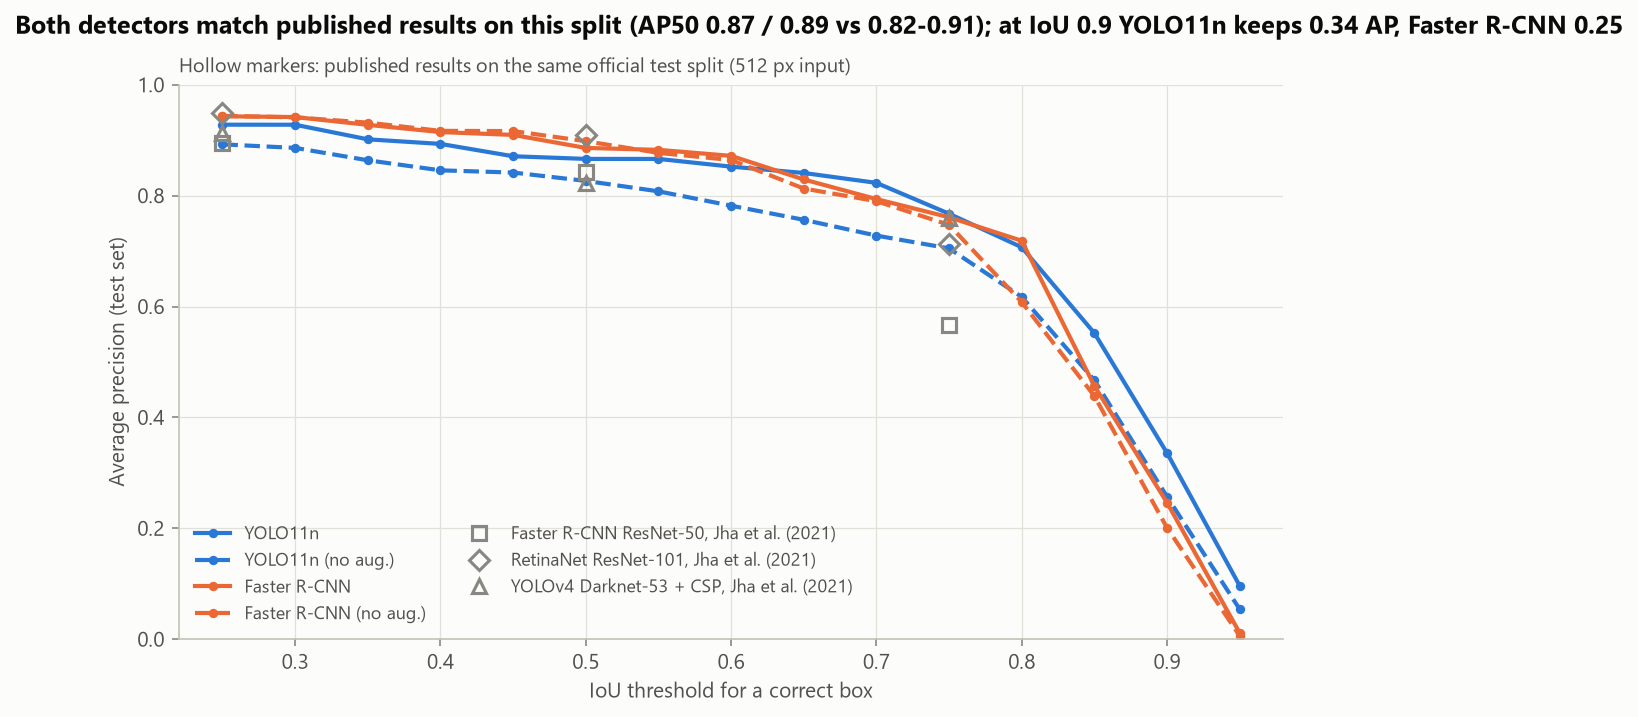

In [13]:
display(Image(FIG / '02_ap_by_iou.png'))

In [14]:
pd.read_csv(RES / 'published_comparison.csv')

,source,model,backbone,input,AP_25_75,AP25,AP50,AP75,fps,fps_hardware
0,"Jha et al. (2021), Table III",Faster R-CNN,ResNet-50,512 x 512,0.787,0.895,0.842,0.566,8.000,Quadro RTX 6000
1,"Jha et al. (2021), Table III",RetinaNet,ResNet-101,512 x 512,0.875,0.948,0.909,0.713,16.800,Quadro RTX 6000
2,"Jha et al. (2021), Table III",YOLOv3 + SPP,Darknet-53,512 x 512,0.810,0.886,0.853,0.759,45.010,Quadro RTX 6000
3,"Jha et al. (2021), Table III",YOLOv4,Darknet-53 + CSP,512 x 512,0.851,0.912,0.823,0.759,48.000,Quadro RTX 6000
4,"Jha et al. (2021), Table III",EfficientDet-D0,EfficientNet-B0 + BiFPN,512 x 512,0.476,0.685,0.505,0.228,35.000,Quadro RTX 6000
5,this project,YOLO11n,YOLO11n (CSP-Darknet style),416 (longer side),0.867,0.928,0.866,0.767,99.170,"RTX 4050 Laptop, batch 1, fp32"
6,this project,YOLO11n (no aug.),YOLO11n (CSP-Darknet style),416 (longer side),0.812,0.892,0.827,0.705,NaN,NaN
7,this project,Faster R-CNN,MobileNetV3-Large FPN,416 (longer side),0.878,0.943,0.886,0.761,76.848,"RTX 4050 Laptop, batch 1, fp32"
8,this project,Faster R-CNN (no aug.),MobileNetV3-Large FPN,416 (longer side),0.876,0.944,0.898,0.747,NaN,NaN


## 5. At a CADe operating point

A deployed detector needs a score threshold. For each model it is set on the validation frames (the score that
maximises F1 at IoU 0.5) and then applied unchanged to the test frames:

| Test set, IoU 0.5 | YOLO11n | Faster R-CNN |
|---|---:|---:|
| Threshold (from validation) | 0.29 | 0.55 |
| Polyps found | 107 / 127 (84.3%) | 110 / 127 (86.6%) |
| False positives | 18 (0.15 per frame) | 12 (0.10 per frame) |
| Precision | 0.856 | 0.902 |

The two detectors mostly miss the same polyps: 14 polyps are missed by both, 6 only by YOLO11n and 3 only by Faster
R-CNN. Every Kvasir-SEG frame contains a polyp, so the false-positive rate on polyp-free frames, which matters
most for alarm fatigue in practice, cannot be measured here.

In [15]:
pd.read_csv(RES / 'operating_point.csv').drop(columns=['key'])

,model,split,threshold,images,polyps,tp,fp,fn,precision,recall,f1,fp_per_image,images_with_hit,mean_iou_tp
0,YOLO11n,val,0.287,100,108,88,16,20,0.846,0.815,0.830,0.160,0.880,0.897
1,YOLO11n,test,0.287,120,127,107,18,20,0.856,0.843,0.849,0.150,0.858,0.880
2,YOLO11n (no aug.),val,0.213,100,108,86,19,22,0.819,0.796,0.808,0.190,0.860,0.860
3,YOLO11n (no aug.),test,0.213,120,127,96,27,31,0.780,0.756,0.768,0.225,0.792,0.868
4,Faster R-CNN,val,0.554,100,108,94,10,14,0.904,0.870,0.887,0.100,0.940,0.855
5,Faster R-CNN,test,0.554,120,127,110,12,17,0.902,0.866,0.884,0.100,0.883,0.862
6,Faster R-CNN (no aug.),val,0.960,100,108,91,7,17,0.929,0.843,0.883,0.070,0.910,0.863
7,Faster R-CNN (no aug.),test,0.960,120,127,101,6,26,0.944,0.795,0.863,0.050,0.825,0.862


In [16]:
pd.read_csv(RES / 'miss_overlap.csv')

,statistic,value
0,test polyps,127
1,missed by YOLO11n only,6
2,missed by Faster R-CNN only,3
3,missed by both,14


## 6. Polyp size

Against expectation, large polyps (> 25% of the frame) score lowest for both detectors (mAP 0.62), with small and
medium polyps at 0.64-0.70; the confidence intervals overlap. At the operating point YOLO11n misses 10 of the 35
large polyps and Faster R-CNN 7, against 7 of 51 small polyps for each. A plausible reason is that a large polyp's
extent is less clear-cut (several lobes, part of it out of view), which is what most of the errors in section 9
look like.

In [17]:
pd.read_csv(RES / 'size_breakdown.csv').drop(columns=['key'])

,model,size,polyps,tp,fn,recall,AP,AP_ci_low,AP_ci_high
0,YOLO11n,small,51,44,7,0.863,0.699,0.617,0.785
1,YOLO11n,medium,41,38,3,0.927,0.695,0.614,0.785
2,YOLO11n,large,35,25,10,0.714,0.619,0.522,0.721
3,YOLO11n (no aug.),small,51,36,15,0.706,0.578,0.495,0.678
4,YOLO11n (no aug.),medium,41,36,5,0.878,0.682,0.591,0.776
5,YOLO11n (no aug.),large,35,24,11,0.686,0.554,0.440,0.671
6,Faster R-CNN,small,51,44,7,0.863,0.644,0.562,0.728
7,Faster R-CNN,medium,41,38,3,0.927,0.693,0.621,0.773
8,Faster R-CNN,large,35,28,7,0.800,0.618,0.520,0.728
9,Faster R-CNN (no aug.),small,51,39,12,0.765,0.649,0.577,0.718


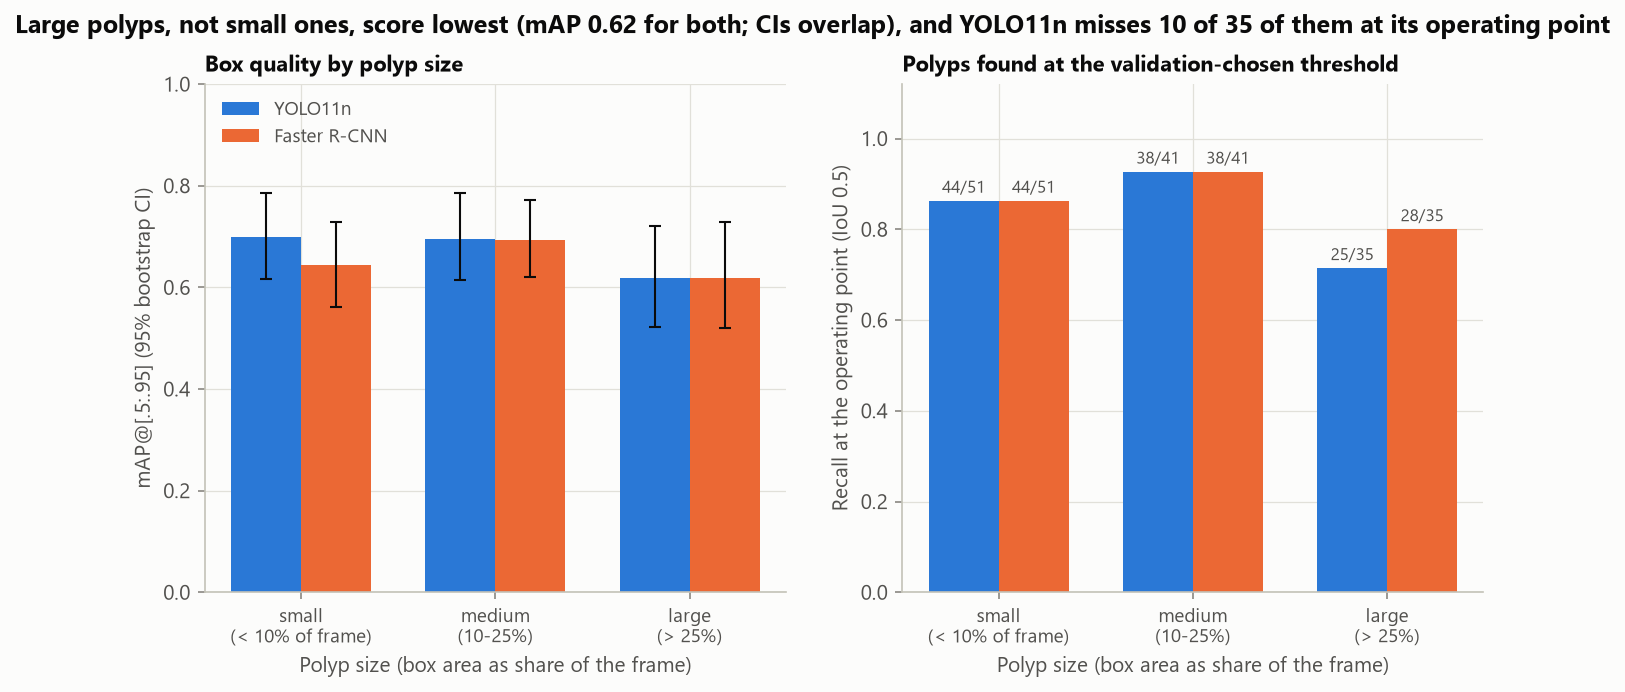

In [18]:
display(Image(FIG / '03_size.png'))

## 7. Augmentation ablation

Switching every augmentation off costs YOLO11n 0.071 mAP@[.5:.95] (0.671 to 0.600, CI of the difference
[+0.029, +0.115], Holm-adjusted p = 0.016, the only significant comparison in the project) and 11 found polyps at
its operating point (107 to 96 with 27 instead of 18 false positives). The loss is largest on small polyps (AP 0.699 to
0.578). Faster R-CNN changes much less: mAP +0.021 with augmentation (not significant), AP50 slightly lower
(0.886 vs 0.898), but 110 instead of 101 polyps found at its operating point. Without augmentation, Faster R-CNN's
training loss falls to 0.26 (0.60 with augmentation) while its validation mAP stays lower, the usual sign of
over-fitting on 780 frames.

In [19]:
m[(m.split == 'test') & (m.ground_truth == 'cleaned')][['model', 'AP', 'AP50', 'AP75', 'AP_small', 'AP_large']]

,model,AP,AP50,AP75,AP_small,AP_large
1,YOLO11n,0.671,0.866,0.767,0.699,0.619
4,YOLO11n (no aug.),0.600,0.827,0.705,0.578,0.554
7,Faster R-CNN,0.646,0.886,0.761,0.644,0.618
10,Faster R-CNN (no aug.),0.624,0.898,0.747,0.649,0.562


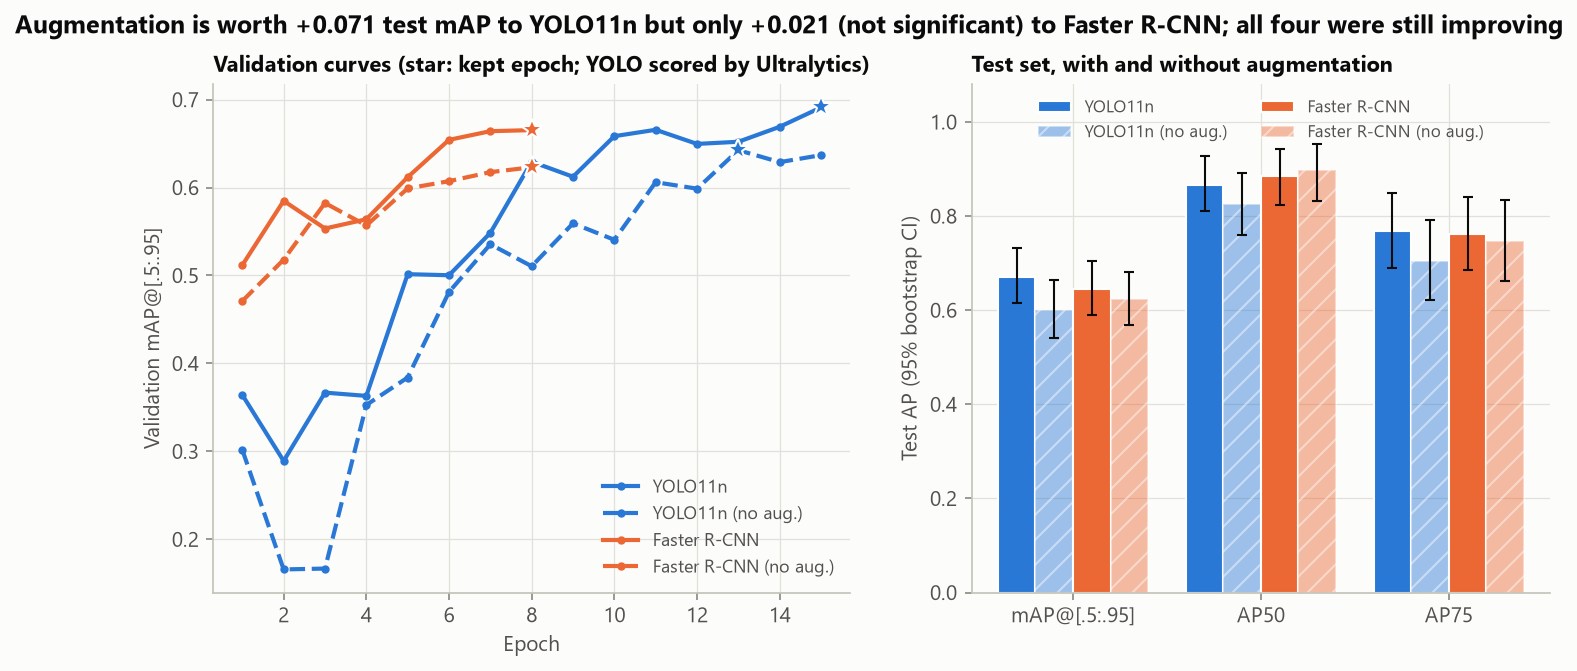

In [20]:
display(Image(FIG / '04_augmentation.png'))

## 8. Speed

Batch-1 latency from a resized image in memory to boxes in memory, measured the same way for both (120 test frames
on the GPU after 10 warm-up frames; 20 frames on 2 CPU threads):

| Median latency | YOLO11n | Faster R-CNN |
|---|---:|---:|
| GPU, fp32 | 8.1 ms | 11.1 ms |
| GPU, fp16 | 9.2 ms | 16.6 ms |
| CPU (2 threads), fp32 | 22.4 ms | 39.2 ms |

YOLO11n is 1.4x faster on the GPU and 1.7x faster on the CPU, with 7x fewer parameters. Half precision does not
help either model at batch 1, and a few very slow fp16 calls push the means to 50 and 79 ms (the cause was not
investigated). Both run well above video frame rate on this laptop GPU.

In [21]:
pd.read_csv(RES / 'speed.csv')

,model,device,precision,median_ms,p90_ms,mean_ms,fps,images
0,YOLO11n,GPU (RTX 4050 Laptop),fp32,8.142,9.874,10.084,99.170,120
1,YOLO11n,GPU (RTX 4050 Laptop),fp16,9.209,15.608,49.898,20.041,120
2,YOLO11n,CPU (2 threads),fp32,22.414,24.757,23.595,42.382,20
3,Faster R-CNN,GPU (RTX 4050 Laptop),fp32,11.100,17.765,13.013,76.848,120
4,Faster R-CNN,GPU (RTX 4050 Laptop),fp16,16.551,30.033,78.947,12.667,120
5,Faster R-CNN,CPU (2 threads),fp32,39.183,42.719,40.068,24.957,20


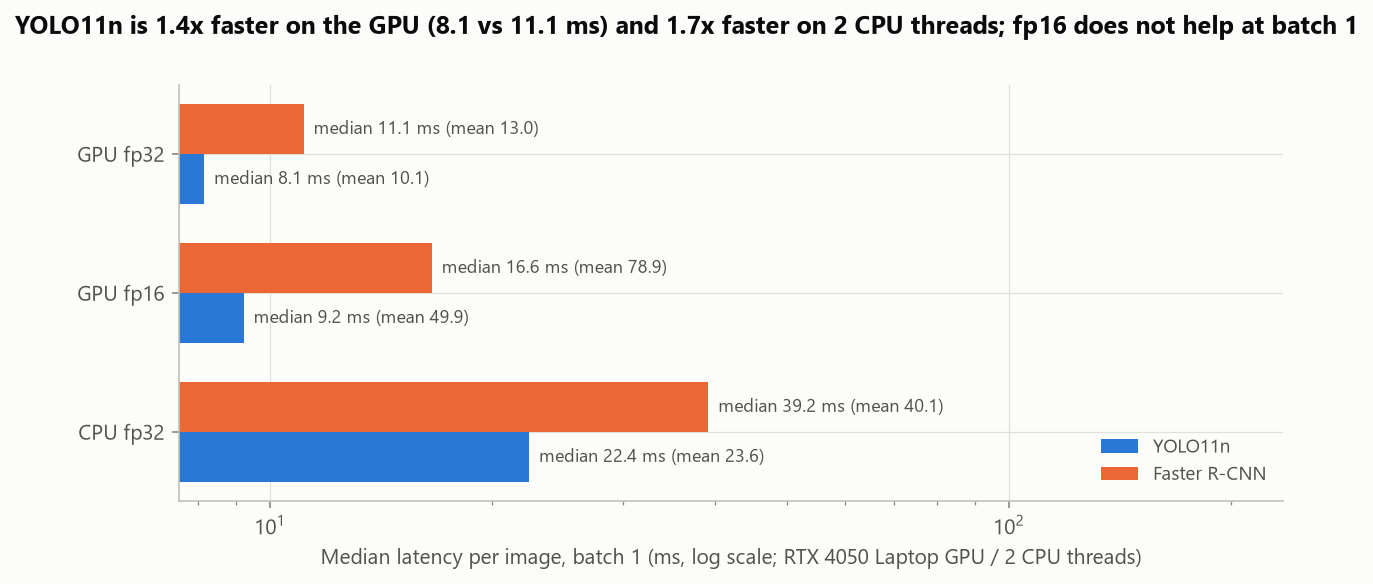

In [22]:
display(Image(FIG / '05_speed.png'))

## 9. What the errors look like

Most false positives are not boxes on healthy mucosa. All 12 of Faster R-CNN's false positives and 16 of YOLO11n's
18 overlap a reference polyp (IoU 0.1-0.5, or a second box on an already-found polyp): the detector boxed one lobe of
a large polyp, or one box around a group that the reference splits. Only two YOLO11n false positives lie on
background. The missed polyps shown include small secondary polyps next to a detected one and low-contrast lesions
on mucosal folds. Many of these "errors" are disagreements about a polyp's extent, which a box-overlap metric counts as both a
false positive and a miss.

In [23]:
e = pd.read_csv(RES / 'error_cases.csv')
e.groupby(['model', 'kind', 'size']).size().unstack('size', fill_value=0)

size                                   large  medium  small
model                  kind                                
Faster R-CNN           false positive      3       5      4
                       missed polyp        7       3      7
Faster R-CNN (no aug.) false positive      1       4      1
                       missed polyp        9       5     12
YOLO11n                false positive      5       6      7
                       missed polyp       10       3      7
YOLO11n (no aug.)      false positive      9       9      9
                       missed polyp       11       5     15

In [24]:
e[e.kind == 'missed polyp'].groupby('model')[['rel_area', 'best_iou']].describe().round(3)

rel_area                                                  best_iou                                                 
                          count   mean    std    min    25%    50%    75%    max    count   mean    std    min    25%    50%    75%    max
model                                                                                                                                     
Faster R-CNN               17.0  0.270  0.294  0.008  0.065  0.130  0.434  0.994     17.0  0.556  0.278  0.000  0.481  0.622  0.755  0.932
Faster R-CNN (no aug.)     26.0  0.252  0.297  0.008  0.053  0.127  0.410  0.994     26.0  0.647  0.257  0.000  0.553  0.743  0.814  0.921
YOLO11n                    20.0  0.342  0.323  0.008  0.085  0.214  0.521  0.997     20.0  0.753  0.144  0.415  0.662  0.770  0.845  0.970
YOLO11n (no aug.)          31.0  0.271  0.313  0.008  0.062  0.125  0.452  0.997     31.0  0.597  0.302  0.000  0.481  0.655  0.842  0.959

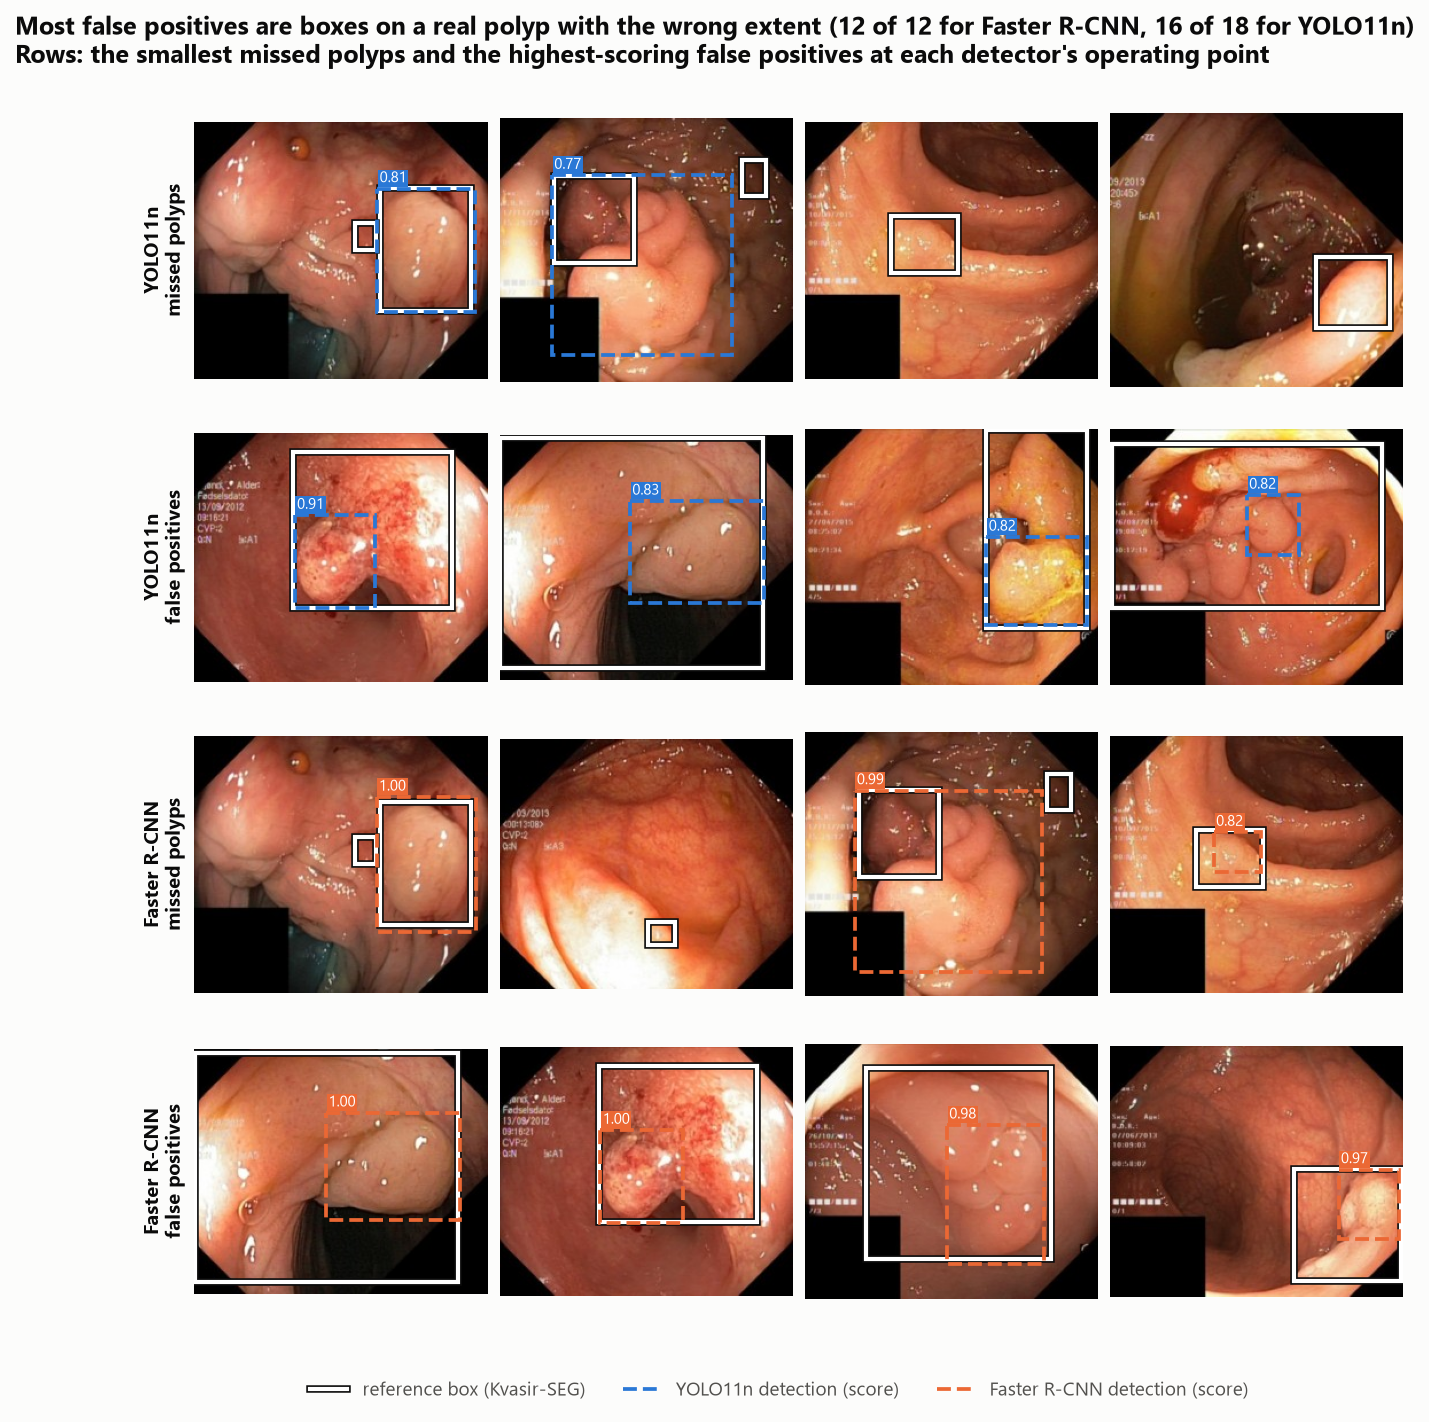

In [25]:
display(Image(FIG / '06_errors.png'))

## 10. Checks

The fast evaluator used for the bootstrap reproduces pycocotools exactly for every model and size bin (largest
absolute difference 0). Keeping the three test-set sliver boxes in the ground truth lowers every model's
mAP@[.5:.95] by 0.013-0.015 and AP50 by about 0.02, and changes no ranking.

In [26]:
pd.read_csv(RES / 'evaluator_check.csv')

,model,area,pycocotools_AP,fast_AP,max_abs_diff_per_iou
0,YOLO11n,all,0.671,0.671,0.0
1,YOLO11n,small,0.699,0.699,0.0
2,YOLO11n,medium,0.695,0.695,0.0
3,YOLO11n,large,0.619,0.619,0.0
4,YOLO11n (no aug.),all,0.600,0.600,0.0
5,YOLO11n (no aug.),small,0.578,0.578,0.0
6,YOLO11n (no aug.),medium,0.682,0.682,0.0
7,YOLO11n (no aug.),large,0.554,0.554,0.0
8,Faster R-CNN,all,0.646,0.646,0.0
9,Faster R-CNN,small,0.644,0.644,0.0


In [27]:
m[(m.split == 'test')].pivot_table(index='model', columns='ground_truth', values=['AP', 'AP50']).round(4)

AP                   AP50        
ground_truth           all JSON boxes cleaned all JSON boxes cleaned
model                                                               
Faster R-CNN                    0.632   0.646          0.867   0.886
Faster R-CNN (no aug.)          0.611   0.624          0.879   0.898
YOLO11n                         0.655   0.671          0.848   0.866
YOLO11n (no aug.)               0.586   0.600          0.808   0.827

## Conclusion

On Kvasir-SEG, with equal data, input size and a short training budget, YOLO11n and a MobileNetV3 Faster R-CNN are
statistically indistinguishable in accuracy (AP50 0.87 vs 0.89, mAP@[.5:.95] 0.67 vs 0.65), and both land in the
range published for larger detectors on the same split. YOLO11n is 1.4-1.7x faster with 7x fewer parameters and
keeps more AP at very strict IoU, but it depends on augmentation far more than Faster R-CNN. The errors that remain
are mostly about where a polyp ends rather than whether it is there. The main caveats: 120 test frames, one seed per
model, short schedules that had not converged, and no polyp-free frames for measuring false alarms.